In [1]:
import sys
from pathlib import Path
import numpy as np
#from numpy.linalg import eigvals, eigvalsh
#from scipy.linalg import eigh
from scipy.sparse.linalg import eigsh,eigs
import matplotlib.pyplot as plt
import math, cmath
import sys
import os
import joblib
from pathlib import Path
import pickle
import time
from mpl_toolkits.mplot3d import Axes3D
from scipy.sparse import csr_matrix, coo_matrix,  bmat, diags, identity, issparse, vstack, hstack

In [2]:
#import sys  
sys.path.insert(1, '\\\\smb.physics.wisc.edu\\smb\\friesen-group\\archives\\avivrekar\\Topological qubit\\Codes\\Spin_Splitting_Ge_ABS')

In [3]:
import Minimal_Model_1D as M
import Minimal_model_1D_1sub as M1sub

In [4]:
hbar = 1.055*10**(-34);   #in J-s
ee = 1.602*10**(-19);     #in C
hbar_mev = hbar/ee*1000   # in meV-s
me = 9.11*10**(-31);      #in kg
hbm = hbar**2*1000/2/me/ee/(1e-18) #in meV (nm)**2

In [13]:
NSM = 300          # in nm
MY = np.array([1,2,4,7])              # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge

MEFF = 0.023

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

NSC = 2000
N = 2*NSC + NSM
PHI = 0.5*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  1 + OMEGA   #in between two subbands
MU_SM =  1 + OMEGA   #in between two subbands

MU_const = 1 + OMEGA

ALPHAT = np.linspace(1, 50, 51)


K = 12

Ep_li_minimal_model = np.empty((ALPHAT.shape[0],K,MY.shape[0]))

for j in range(MY.shape[0]):

    for i in range(ALPHAT.shape[0]):

        if MY[j] == 1:

            Fli = M1sub.Model(N ,NSM, NSC, AX ,OMEGA, ALPHAT[i], DELTA, MEFF,  MU_const, phi=PHI)

            Hli = Fli.H_sys()

        else:
            Fli = M.oneD_Minimal_Model(N ,NSM, NSC,MY[j],AX ,OMEGA, ALPHAT[i], DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)
            
            Hli = Fli.H_sys(PHI, so = 'li', on_both_junc=False)

        Eli = eigsh(Hli ,k=K,sigma=0, return_eigenvectors=False)
        
        Eli = np.sort(Eli)
        
        Ep_li_minimal_model[i,:,j] = Eli
        
        if i%5==0:
            print(i)

first subband energy = 1.3263440267269595 
 second subband energy = 2.652688053453919
0
5
10
15
20
25
30
35
40
45
50
0
5
10
15
20
25
30
35
40
45
50
0
5
10
15
20
25
30
35
40
45
50
0
5
10
15
20
25
30
35
40
45
50


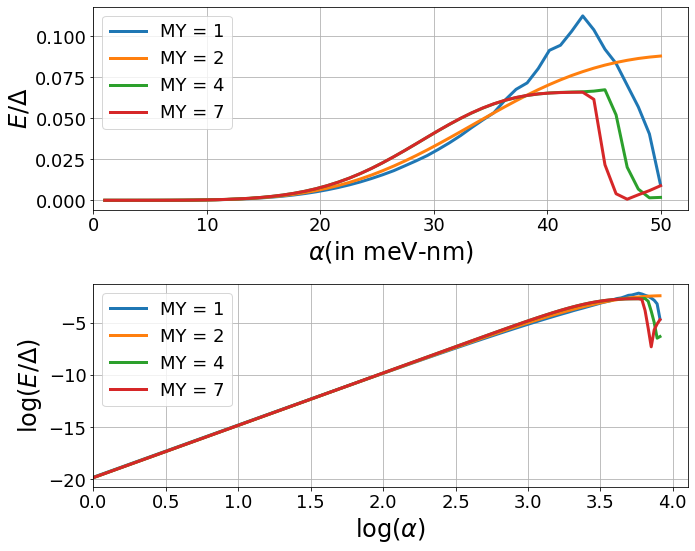

In [14]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

Ep_Split_li_minimal_model = Ep_li_minimal_model[:,K//2+1,:] - Ep_li_minimal_model[:,K//2,:]


plt.subplot(2,1,1)
#plt.plot((ALPHAT), (Ep_Split_li/DELTA), lw=3 ,linestyle ='-' , color='blue')
for j in range(MY.shape[0]):
    plt.plot((ALPHAT), (Ep_Split_li_minimal_model[:,j]/DELTA), lw=3, label='MY = %i'%MY[j] )
plt.xlabel(r'$\alpha$(in meV-nm)', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)
plt.grid(True)
plt.legend()
plt.xlim(left=0)

plt.subplot(2,1,2)
for j in range(MY.shape[0]):
    plt.plot(np.log(ALPHAT), np.log(Ep_Split_li_minimal_model[:,j]/DELTA), lw=3, label='MY = %i'%MY[j])
plt.xlabel(r'log($\alpha$)', fontsize=24)
plt.ylabel(r'log($E/\Delta$)', fontsize=24)
plt.legend()
plt.xlim(left=0)
plt.grid(True)

plt.tight_layout()

plt.show()

In [15]:
# Save the array to a file
np.save('Ep_split_li_4MYs.npy',Ep_Split_li_minimal_model )

In [18]:
Ep_Split_li = np.load('Ep_split_li_4MYs.npy')

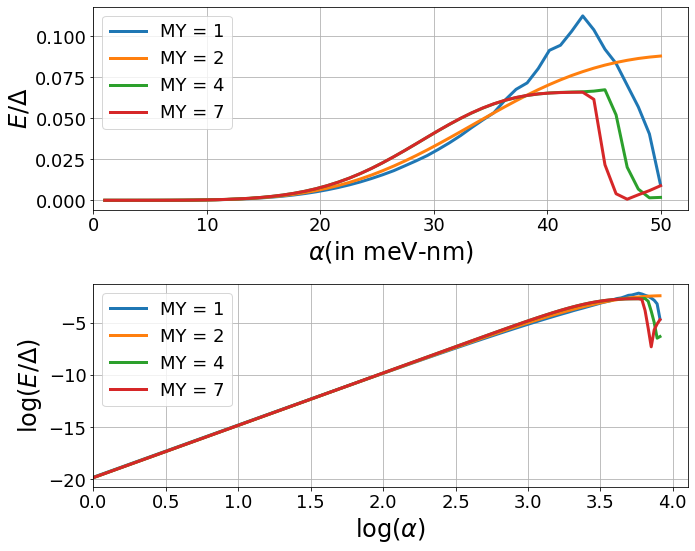

In [19]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

#Ep_Split_li_minimal_model = Ep_li_minimal_model[:,K//2+1,:] - Ep_li_minimal_model[:,K//2,:]


plt.subplot(2,1,1)
#plt.plot((ALPHAT), (Ep_Split_li/DELTA), lw=3 ,linestyle ='-' , color='blue')
for j in range(MY.shape[0]):
    plt.plot((ALPHAT), (Ep_Split_li[:,j]/DELTA), lw=3, label='MY = %i'%MY[j] )
plt.xlabel(r'$\alpha$(in meV-nm)', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)
plt.grid(True)
plt.legend()
plt.xlim(left=0)

plt.subplot(2,1,2)
for j in range(MY.shape[0]):
    plt.plot(np.log(ALPHAT), np.log(Ep_Split_li[:,j]/DELTA), lw=3, label='MY = %i'%MY[j])
plt.xlabel(r'log($\alpha$)', fontsize=24)
plt.ylabel(r'log($E/\Delta$)', fontsize=24)
plt.legend()
plt.xlim(left=0)
plt.grid(True)

plt.tight_layout()

plt.show()

Checking if in above plots the mass inversion point corresponds to the change in behavior and sharp kink of the one subband effective model plot

In [9]:
NSM = 300          # in nm
#MY = np.array([1,2,4,7])              # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge

MEFF = 0.023

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

NSC = 2000
N = 2*NSC + NSM
PHI = 0.5*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

#MU_SC =  1 + OMEGA   #in between two subbands
#MU_SM =  1 + OMEGA   #in between two subbands

MU_const = 1 + OMEGA

ALPHAT = np.linspace(1, 100, 21)

for i in range(ALPHAT.shape[0]):

    Fli = M1sub.Model(N ,NSM, NSC, AX ,OMEGA, ALPHAT[i], DELTA, MEFF,  MU_const, phi=PHI)

    MMEFF = Fli.Modified_Eff_mass()

    print(ALPHAT[i],'\t', MMEFF,'\n')

first subband energy = 1.3263440267269595 
 second subband energy = 2.652688053453919
1.0 	 0.023000004753209725 

5.95 	 0.02300582178963124 

10.9 	 0.0230622132777989 

15.850000000000001 	 0.023258092576275802 

20.8 	 0.02370075827607608 

25.75 	 0.024500210369173353 

30.700000000000003 	 0.025772691486930555 

35.65 	 0.027661500313708065 

40.6 	 0.030375121208480675 

45.550000000000004 	 0.034255051246246275 

50.5 	 0.03991384289208414 

55.45 	 0.048565117422126304 

60.400000000000006 	 0.06297510174981422 

65.35000000000001 	 0.09105374393831224 

70.3 	 0.16801449061530524 

75.25 	 1.2081856146227858 

80.2 	 -0.22941891621174818 

85.15 	 -0.1043405300883035 

90.10000000000001 	 -0.06743077368346274 

95.05 	 -0.0497915401861366 

100.0 	 -0.039470283803054035 



In [8]:
Fli = M1sub.Model(N ,NSM, NSC, AX ,OMEGA, ALPHAT[i], DELTA, MEFF,  MU_const, phi=PHI)

ALPHASTAR = Fli.Approx_alpha_inversion()

print(ALPHASTAR)

Note that Alpha_kappa is ignored in comparison to Ey- in this calculation
Ey-(meV) = 0.6631720133634798 	 Alpha*Kappa(meV) =  0.7071067811865476
64.28997323116594
